# Age estimation on the ageing speakers (80/20 split) — 4 s and 5 s windows


In [1]:
import json
import multiprocessing as mp
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, median_absolute_error, r2_score, accuracy_score
from sklearn.svm import SVC, SVR
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.cross_decomposition import PLSRegression

## Constants, paths, models 

In [2]:
RANDOM_STATE = 12
SVM_MAX_TRAIN = 8000
N_JOBS_RF = 6
SAVE_MODELS = False

FEATURE_PARTS_4S = sorted(Path(".").glob("features_pool_4s_261_part*of6.parquet"))
FEATURE_PARTS_5S = sorted(Path(".").glob("features_261_5s_part*of2.parquet"))
assert len(FEATURE_PARTS_4S) == 6, FEATURE_PARTS_4S
assert len(FEATURE_PARTS_5S) == 2, FEATURE_PARTS_5S
DURATIONS = {"4sec": FEATURE_PARTS_4S, "5sec": FEATURE_PARTS_5S}
JOBS = [("4sec", "male"), ("4sec", "female"), ("5sec", "male"), ("5sec", "female")]
META_COLS = ["VoxCeleb_ID", "video_id", "utterance_id", "gender", "speaker_age", "subset", "wav_path"]

OUT = Path("repro_5age")
MODELS_DIR = OUT / "models"
RESULTS_DIR = OUT / "results"

# 261 descriptors = all non-metadata columns, sorted by name
_columns = pd.read_parquet(FEATURE_PARTS_5S[0]).columns
FEATS = sorted(c for c in _columns if c not in META_COLS)
assert len(FEATS) == 261
_columns_4s = pd.read_parquet(DURATIONS["4sec"][0]).columns
assert set(FEATS) == {c for c in _columns_4s if c not in META_COLS}

CLASSIFIERS = {
    "SVC":          (lambda: make_pipeline(StandardScaler(),
                        SVC(C=10.0, gamma="scale", cache_size=1000)), True),
    "RandomForest": (lambda: RandomForestClassifier(
                        n_estimators=300, n_jobs=N_JOBS_RF, random_state=RANDOM_STATE), False),
}
REGRESSORS = {
    "LinearRegression": (lambda: make_pipeline(StandardScaler(), LinearRegression()), False),
    "Ridge":            (lambda: make_pipeline(StandardScaler(), Ridge(alpha=10.0,
                            random_state=RANDOM_STATE)), False),
    "PLS":              (lambda: make_pipeline(StandardScaler(),
                            PLSRegression(n_components=30)), False),
    "SVR":              (lambda: make_pipeline(StandardScaler(),
                            SVR(C=10.0, gamma="scale", cache_size=1000)), True),
    "RandomForest":     (lambda: RandomForestRegressor(
                            n_estimators=300, n_jobs=N_JOBS_RF, random_state=RANDOM_STATE), False),
}
for duration, parts in DURATIONS.items():
    print(duration, [p.name for p in parts])
print(f"{len(FEATS)} features")

4sec ['features_pool_4s_261_part1of6.parquet', 'features_pool_4s_261_part2of6.parquet', 'features_pool_4s_261_part3of6.parquet', 'features_pool_4s_261_part4of6.parquet', 'features_pool_4s_261_part5of6.parquet', 'features_pool_4s_261_part6of6.parquet']
5sec ['features_261_5s_part1of2.parquet', 'features_261_5s_part2of2.parquet']
261 features


## Functions 

In [3]:
def select_aging_speakers(frame, min_age_range=5):
    """VoxCeleb_IDs whose recordings span >= `min_age_range` years."""
    span = frame.groupby("VoxCeleb_ID")["speaker_age"].agg(lambda s: s.max() - s.min())
    return span[span >= min_age_range].index


def extract_features_and_age(frame):
    return frame[FEATS].fillna(0.0).to_numpy(), frame["speaker_age"].to_numpy()


def maybe_subsample(features, labels, kernel):
    """Kernel models are fitted on at most SVM_MAX_TRAIN training rows."""
    if not kernel or len(features) <= SVM_MAX_TRAIN:
        return features, labels, len(features)
    rng = np.random.RandomState(RANDOM_STATE)
    sample_idx = rng.choice(len(features), SVM_MAX_TRAIN, replace=False)
    return features[sample_idx], labels[sample_idx], SVM_MAX_TRAIN


def read_features(duration):
    """Concatenate the parquet parts of one window."""
    frame = pd.concat([pd.read_parquet(p) for p in DURATIONS[duration]], ignore_index=True)
    if "utterance_id" in frame:
        assert frame["utterance_id"].is_unique
    return frame


def load(duration):
    frame = read_features(duration)
    return frame[frame["gender"].isin(["male", "female"])].reset_index(drop=True)


def make_split(duration="5sec"):
    """bak-5sec cell 5: the ageing speakers of each gender are split 80/20 by speaker ID."""
    data = read_features(duration)
    split = {}
    for gender in ["female", "male"]:
        g = data[data["gender"] == gender]
        aging = select_aging_speakers(g, min_age_range=5)
        train_id, test_id = train_test_split(aging.values, test_size=0.2, random_state=12)
        split[gender] = {"aging_all": sorted(aging.values.tolist()),
                         "aging_train": sorted(train_id.tolist()),
                         "aging_test": sorted(test_id.tolist())}
    return split


def regime_a_split(frame, gender, test_ids):
    """Train = every speaker of `gender` except the held-out test IDs; test = the held-out IDs."""
    gender_frame = frame[frame["gender"] == gender]
    train_df = gender_frame[~gender_frame["VoxCeleb_ID"].isin(test_ids)]
    test_df = gender_frame[gender_frame["VoxCeleb_ID"].isin(test_ids)]
    return train_df.reset_index(drop=True), test_df.reset_index(drop=True)


def run_job(args):
    """Fit and score every classifier and regressor for one (window, gender) pair."""
    duration, gender, test_ids = args
    out_csv = RESULTS_DIR / f"results_{duration}_{gender}.csv"
    frame = load(duration)
    train_df, test_df = regime_a_split(frame, gender, set(test_ids))
    x_train, y_train = extract_features_and_age(train_df)
    x_test, y_test = extract_features_and_age(test_df)
    common = {"duration": duration, "gender": gender,
              "n_train_spk": train_df["VoxCeleb_ID"].nunique(), "n_test": len(y_test),
              "n_test_spk": test_df["VoxCeleb_ID"].nunique()}
    rows = []

    # classification: each integer age is a class
    for name, (factory, kernel) in CLASSIFIERS.items():
        y_int = np.rint(y_train).astype(int)
        le = LabelEncoder().fit(y_int)
        model = factory()
        model.fit(x_train, le.transform(y_int))
        if SAVE_MODELS:
            joblib.dump({"pipeline": model, "label_encoder": le, "features": FEATS},
                        MODELS_DIR / f"cls_{duration}_{gender}_{name}.joblib")
        pred = le.inverse_transform(model.predict(x_test)).astype(float)
        rows.append({**common, "model": name, "framing": "classification", "n_train": len(y_train),
                     "MAE": mean_absolute_error(y_test, pred),
                     "median_ae": median_absolute_error(y_test, pred),
                     "exact_acc": accuracy_score(np.rint(y_test).astype(int), np.rint(pred).astype(int)),
                     "within5_acc": float(np.mean(np.abs(pred - y_test) <= 5)),
                     "R2": r2_score(y_test, pred)})

    # naive baseline: the training median for every test recording
    baseline = np.full_like(y_test, np.median(y_train))
    rows.append({**common, "model": "median-baseline", "framing": "regression", "n_train": len(y_train),
                 "MAE": mean_absolute_error(y_test, baseline),
                 "median_ae": median_absolute_error(y_test, baseline), "exact_acc": np.nan,
                 "within5_acc": float(np.mean(np.abs(baseline - y_test) <= 5)),
                 "R2": r2_score(y_test, baseline)})

    # regression: age as a continuous target
    for name, (factory, kernel) in REGRESSORS.items():
        x_fit, y_fit, n_used = maybe_subsample(x_train, y_train, kernel)
        model = factory()
        model.fit(x_fit, y_fit)
        if SAVE_MODELS:
            joblib.dump({"model": model, "features": FEATS, "n_train": n_used},
                        MODELS_DIR / f"reg_{duration}_{gender}_{name}.joblib")
        pred = np.asarray(model.predict(x_test)).ravel().astype(float)
        rows.append({**common, "model": name, "framing": "regression", "n_train": n_used,
                     "MAE": mean_absolute_error(y_test, pred),
                     "median_ae": median_absolute_error(y_test, pred), "exact_acc": np.nan,
                     "within5_acc": float(np.mean(np.abs(pred - y_test) <= 5)),
                     "R2": r2_score(y_test, pred)})

    pd.DataFrame(rows).to_csv(out_csv, index=False)
    return f"saved: {out_csv}"

## 80/20 split of the ageing speakers


In [4]:
OUT.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)
split = make_split("5sec")
(OUT / "split_ageing_80_20.json").write_text(json.dumps(split, indent=1))
assert make_split("4sec") == split, "4 s and 5 s tables give different splits"

for duration in DURATIONS:
    frame = load(duration)
    print(f"--- {duration}: {len(frame)} recordings")
    for g in ["male", "female"]:
        train_df, test_df = regime_a_split(frame, g, set(split[g]["aging_test"]))
        train_spk, test_spk = set(train_df["VoxCeleb_ID"]), set(test_df["VoxCeleb_ID"])
        n_ageing_train = len(train_spk & set(split[g]["aging_train"]))
        print(f"{g:6s} | ageing speakers: {len(split[g]['aging_all'])} = "
              f"{len(split[g]['aging_train'])} in train + {len(split[g]['aging_test'])} in test")
        print(f"       | train: {len(train_spk)} speakers ({len(train_spk) - n_ageing_train} non-ageing + "
              f"{n_ageing_train} ageing), {len(train_df)} recordings")
        print(f"       | test:  {len(test_spk)} speakers (all ageing), {len(test_df)} recordings")
        assert not (train_spk & test_spk), "speaker in both train and test"

--- 4sec: 47763 recordings
male   | ageing speakers: 197 = 157 in train + 40 in test
       | train: 1672 speakers (1515 non-ageing + 157 ageing), 28601 recordings
       | test:  40 speakers (all ageing), 1573 recordings
female | ageing speakers: 137 = 109 in train + 28 in test
       | train: 1071 speakers (962 non-ageing + 109 ageing), 16854 recordings
       | test:  28 speakers (all ageing), 735 recordings
--- 5sec: 47763 recordings
male   | ageing speakers: 197 = 157 in train + 40 in test
       | train: 1672 speakers (1515 non-ageing + 157 ageing), 28601 recordings
       | test:  40 speakers (all ageing), 1573 recordings
female | ageing speakers: 137 = 109 in train + 28 in test
       | train: 1071 speakers (962 non-ageing + 109 ageing), 16854 recordings
       | test:  28 speakers (all ageing), 735 recordings


## Training and evaluation: 2 windows (4 s, 5 s) x 2 genders, in parallel

In [5]:
# a (window, gender) pair is computed only if its results file does not exist yet
jobs = []
for d, g in JOBS:
    out_csv = RESULTS_DIR / f"results_{d}_{g}.csv"
    if out_csv.exists():
        print(f"exists, not recomputed: {out_csv}")
    else:
        jobs.append((d, g, split[g]["aging_test"]))

if jobs:
    with mp.get_context("fork").Pool(len(jobs)) as pool:
        for message in pool.imap_unordered(run_job, jobs):
            print(message, flush=True)

exists, not recomputed: repro_5age/results/results_4sec_male.csv
exists, not recomputed: repro_5age/results/results_4sec_female.csv
exists, not recomputed: repro_5age/results/results_5sec_male.csv
exists, not recomputed: repro_5age/results/results_5sec_female.csv


## All results

`cls_df` and `reg_df` collect the per-(window, gender) results written above
(loop over windows, then genders, then models).

In [6]:
per_pair = {(d, g): pd.read_csv(RESULTS_DIR / f"results_{d}_{g}.csv") for d, g in JOBS}
cls_df = pd.concat([per_pair[(d, g)].query("framing == 'classification'")
                    for d, g in JOBS], ignore_index=True)
reg_df = pd.concat([per_pair[(d, g)].query("framing == 'regression'")
                    for d, g in JOBS], ignore_index=True)

for row in cls_df.itertuples():
    print(f"[cls] {row.duration} {row.gender:6s} {row.model:13s} n_train={row.n_train:>6,} "
          f"MAE={row.MAE:5.2f} median_ae={row.median_ae:4.1f} "
          f"exact={row.exact_acc:.3f} within5={row.within5_acc:.3f}")
for row in reg_df.query("model != 'median-baseline'").itertuples():
    print(f"[reg] {row.duration} {row.gender:6s} {row.model:17s} n_train={row.n_train:>6,} "
          f"MAE={row.MAE:5.2f} median_ae={row.median_ae:4.1f} R2={row.R2:+.3f}")

all_csv = RESULTS_DIR / "results_all.csv"
pd.concat([cls_df, reg_df], ignore_index=True).to_csv(all_csv, index=False)
print("saved", all_csv)

[cls] 4sec male   SVC           n_train=28,601 MAE=10.64 median_ae= 8.0 exact=0.028 within5=0.388
[cls] 4sec male   RandomForest  n_train=28,601 MAE=11.30 median_ae= 9.0 exact=0.024 within5=0.367
[cls] 4sec female SVC           n_train=16,854 MAE= 9.08 median_ae= 8.0 exact=0.046 within5=0.371
[cls] 4sec female RandomForest  n_train=16,854 MAE=10.14 median_ae= 9.0 exact=0.024 within5=0.348
[cls] 5sec male   SVC           n_train=28,601 MAE=10.55 median_ae= 7.0 exact=0.020 within5=0.405
[cls] 5sec male   RandomForest  n_train=28,601 MAE=11.05 median_ae= 9.0 exact=0.024 within5=0.370
[cls] 5sec female SVC           n_train=16,854 MAE= 8.94 median_ae= 7.0 exact=0.049 within5=0.380
[cls] 5sec female RandomForest  n_train=16,854 MAE= 9.73 median_ae= 8.0 exact=0.030 within5=0.344
[reg] 4sec male   LinearRegression  n_train=28,601 MAE= 8.83 median_ae= 7.8 R2=+0.287
[reg] 4sec male   Ridge             n_train=28,601 MAE= 8.83 median_ae= 7.8 R2=+0.287
[reg] 4sec male   PLS               n_train=

## Comparison tables — ranked by MAE

In [7]:
results = pd.concat([cls_df, reg_df], ignore_index=True)
results = results[["duration", "gender", "framing", "model", "n_train",
                   "MAE", "median_ae", "R2"]]

ranked = results.sort_values("MAE").reset_index(drop=True)
print("All fits by MAE (best first):")
display(ranked.round(3))

# MAE vs duration, one pivot per gender (rows = framing|model, cols = duration).
for gender in ["male", "female"]:
    gender_df = results[results["gender"] == gender]
    pivot = (gender_df.assign(key=gender_df["framing"].str[:3] + " | " + gender_df["model"])
                      .pivot_table(index="key", columns="duration", values="MAE"))
    pivot = pivot[[d for d in DURATIONS if d in pivot.columns]]                       # keep window column order
    pivot["mean"] = pivot.mean(axis=1)
    print(f"\nMAE by model x duration -- {gender} (sorted by mean):")
    display(pivot.sort_values("mean").round(3))

All fits by MAE (best first):


,duration,gender,framing,model,n_train,MAE,median_ae,R2
0,4sec,female,regression,SVR,8000,7.407,6.301,0.338
1,5sec,female,regression,SVR,8000,7.578,6.356,0.304
2,5sec,female,regression,PLS,16854,8.059,6.982,0.243
3,5sec,female,regression,Ridge,16854,8.114,7.173,0.236
4,5sec,female,regression,LinearRegression,16854,8.122,7.108,0.235
5,4sec,female,regression,PLS,16854,8.176,7.372,0.222
6,4sec,female,regression,Ridge,16854,8.218,7.332,0.216
7,4sec,female,regression,LinearRegression,16854,8.231,7.382,0.213
8,5sec,female,regression,RandomForest,16854,8.590,7.717,0.124
9,5sec,male,regression,SVR,8000,8.713,7.307,0.259



MAE by model x duration -- male (sorted by mean):


duration,4sec,5sec,mean
key,,,
reg | Ridge,8.828,8.723,8.775
reg | LinearRegression,8.828,8.729,8.779
reg | PLS,8.861,8.754,8.807
reg | SVR,8.931,8.713,8.822
reg | RandomForest,9.545,9.491,9.518
cla | SVC,10.639,10.545,10.592
reg | median-baseline,10.692,10.692,10.692
cla | RandomForest,11.297,11.054,11.175



MAE by model x duration -- female (sorted by mean):


duration,4sec,5sec,mean
key,,,
reg | SVR,7.407,7.578,7.492
reg | PLS,8.176,8.059,8.118
reg | Ridge,8.218,8.114,8.166
reg | LinearRegression,8.231,8.122,8.176
reg | RandomForest,8.866,8.590,8.728
cla | SVC,9.082,8.944,9.013
cla | RandomForest,10.141,9.735,9.938
reg | median-baseline,10.005,10.005,10.005


## MAE per model — one panel per (window, gender)

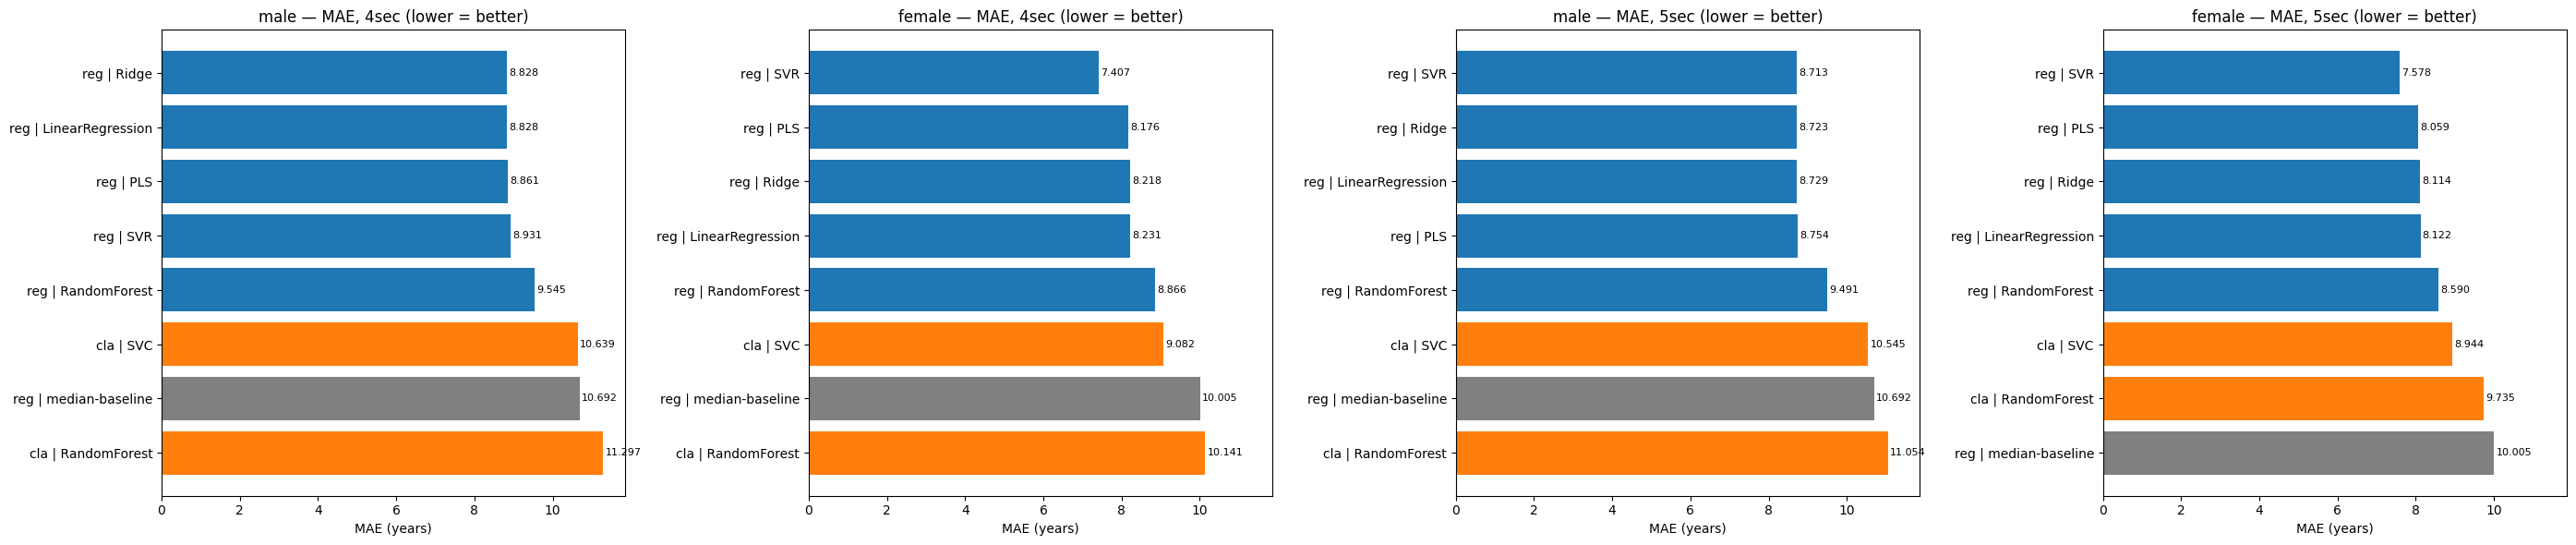

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, len(JOBS), figsize=(7 * len(JOBS), 6), sharex=True)
for ax, (duration, gender) in zip(axes, JOBS):
    gender_df = (results[(results["gender"] == gender) & (results["duration"] == duration)]
                 .sort_values("MAE", ascending=False))
    labels = gender_df["framing"].str[:3] + " | " + gender_df["model"]
    colors = ["grey" if m == "median-baseline" else
              ("tab:orange" if f == "classification" else "tab:blue")
              for f, m in zip(gender_df["framing"], gender_df["model"])]
    ax.barh(labels, gender_df["MAE"], color=colors)
    for y, mae in enumerate(gender_df["MAE"]):
        ax.text(mae + 0.05, y, f"{mae:.3f}", va="center", fontsize=8)
    ax.set_title(f"{gender} — MAE, {duration} (lower = better)")
    ax.set_xlabel("MAE (years)")
plt.tight_layout()
plt.show()

## Values reported in the abstract

Best model per gender: female — SVR on 4 s windows, male — Ridge on 5 s windows.

In [9]:
ABSTRACT = {("female", "4sec", "regression", "SVR"): 7.407,
         ("male",   "5sec", "regression", "Ridge"): 8.723}
for (gender, duration, framing, model), mae_paper in ABSTRACT.items():
    row = results.query("gender == @gender and duration == @duration and "
                        "framing == @framing and model == @model").iloc[0]
    print(f"{gender:6s} {duration} {model:5s}  MAE = {row.MAE:.3f}  (abstract: {mae_paper:.3f})  "
          f"median AE = {row.median_ae:.2f}  R2 = {row.R2:.3f}  n_train = {row.n_train:,}")
    assert round(row.MAE, 3) == mae_paper


female 4sec SVR    MAE = 7.407  (abstract: 7.407)  median AE = 6.30  R2 = 0.338  n_train = 8,000
male   5sec Ridge  MAE = 8.723  (abstract: 8.723)  median AE = 7.52  R2 = 0.306  n_train = 28,601
